# TP Web Mining — Análisis 2 · Notebook 2b: modelos sin futuros

Predicción del precio disponible Matba (Rosario) de soja, maíz y trigo a 30, 60 y 90 días, **usando solo disponible, Chicago y lluvia del Corn Belt**. Ningún dato de precios futuros entra en este notebook.

Parte de `panel_sin_futuros.csv` y `variables_diarias.csv`, que genera el Notebook 1b.

**Modelos**

| Modelo | Qué es |
|---|---|
| **ElasticNet** | Regresión lineal regularizada: descarta sola las variables que no aportan |
| **XGBoost** | Árboles de decisión potenciados, muy regularizados |
| **ARIMA** | Serie de tiempo pura del disponible (d = 1) |
| **ARIMAX** | ARIMA + Chicago y clima como variables externas (rezagadas) |

**Benchmarks:** random walk ("el precio no cambia") y tendencia promedio.

**Aporte de cada fuente.** ElasticNet y XGBoost se entrenan con tres conjuntos de variables, que se van sumando:

| Conjunto | Variables |
|---|---|
| `precio` | propio disponible + calendario |
| `chicago` | `precio` + Chicago |
| `completo` | `chicago` + clima Corn Belt |

Así se ve cuánto mejora (o empeora) la predicción al agregar Chicago y después el clima.

**Esquema:** tuning solo con 2023-2024; test walk-forward mensual desde 2025; métricas sobre la misma muestra para todos los modelos. Al final, un **pronóstico real** a 30, 60 y 90 días desde la última fecha con dato.

Tiempo estimado en Colab: unos 5-10 minutos, casi todo en ARIMA/ARIMAX.

## 0. Configuración y carga

Si corriste el Notebook 1b en la misma sesión, los archivos ya están en `/content`. Si no, la celda los pide.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

IN_COLAB = "google.colab" in sys.modules
DATA_DIR = os.environ.get("DATA_DIR", "/content" if IN_COLAB else "../data/processed")  # lo que genera el notebook 01
RES_DIR  = os.environ.get("RES_DIR",  "/content" if IN_COLAB else "../resultados")
os.makedirs(RES_DIR, exist_ok=True)
RUTA_PANEL = os.path.join(DATA_DIR, "panel_sin_futuros.csv")
RUTA_DIARIAS = os.path.join(DATA_DIR, "variables_diarias.csv")

if not (os.path.exists(RUTA_PANEL) and os.path.exists(RUTA_DIARIAS)) and IN_COLAB:
    from google.colab import files
    print("Subí panel_sin_futuros.csv y variables_diarias.csv (los genera el Notebook 1b)")
    files.upload()
assert os.path.exists(RUTA_PANEL) and os.path.exists(RUTA_DIARIAS), f"Faltan archivos en {DATA_DIR}"

panel = pd.read_csv(RUTA_PANEL, parse_dates=["fecha", "fecha_obj"])
diarias = pd.read_csv(RUTA_DIARIAS, parse_dates=["fecha"]).sort_values(["especie", "fecha"])
assert not any("fut" in c.lower() for c in panel.columns), "El panel trae columnas de futuros"
print(panel.shape, panel.fecha.min().date(), "→", panel.fecha.max().date())

(7794, 26) 2023-01-02 → 2026-08-25


In [2]:
HORIZONTES  = [30, 60, 90]
ESPECIES    = ["soja", "maiz", "trigo"]
FIN_TUNING  = pd.Timestamp("2024-12-31")
INICIO_TEST = pd.Timestamp("2025-01-01")
SEMILLA     = 42

VARS_PRECIO   = ["ret_5", "ret_21", "ret_63", "vol_21", "dist_ma63", "mes_sin", "mes_cos"] + \
                [c for c in panel.columns if c.startswith("reg_")]
VARS_CHICAGO  = ["chi_ret_5", "chi_ret_21", "chi_ret_63", "base", "base_desvio"]
VARS_CLIMA    = ["anom_acum30", "anom_acum60", "critico", "clima_x_critico"]
CONJUNTOS = {
    "precio":   VARS_PRECIO,
    "chicago":  VARS_PRECIO + VARS_CHICAGO,
    "completo": VARS_PRECIO + VARS_CHICAGO + VARS_CLIMA,
}

# Un solo modelo para las tres especies: la especie entra como variable (dummies)
def agregar_dummies(df):
    for esp in ["soja", "trigo"]:            # maíz queda como base
        df[f"esp_{esp}"] = (df.especie == esp).astype(float)
    return df
panel = agregar_dummies(panel)
diarias = agregar_dummies(diarias)
ultimas = diarias.groupby("especie").tail(1)   # último día con dato, por especie
VARS_ESP = ["esp_soja", "esp_trigo"]

# Filas utilizables: todas las variables del conjunto completo presentes (mismas filas para todos los modelos)
panel = panel.dropna(subset=CONJUNTOS["completo"] + ["y"]).reset_index(drop=True)
print("Filas utilizables:", len(panel))
print(panel.groupby(["h", "conjunto"]).size().unstack())

Filas utilizables: 7209
conjunto  purga  test  tuning
h                            
30           57  1191    1215
60          117  1128    1155
90          180  1074    1092


## 1. Métricas

`R2_oos_vs_RW` > 0 significa que el modelo le gana al random walk. `DM_p_vs_RW` < 0.05 con `DM_stat_vs_RW` < 0 significa que le gana de forma estadísticamente significativa.

In [3]:
def diebold_mariano(e_modelo, e_bench, h_ruedas):
    # H0: igual error cuadrático. Estadístico < 0 => el modelo tiene menor error que el benchmark
    d = np.asarray(e_modelo) ** 2 - np.asarray(e_bench) ** 2
    T = len(d)
    if T < 10 or np.allclose(d, 0):
        return np.nan, np.nan
    dc = d - d.mean()
    lag = max(int(h_ruedas) - 1, 0)
    gamma = [dc @ dc / T] + [dc[k:] @ dc[:-k] / T for k in range(1, lag + 1)]
    var = gamma[0] + 2 * sum((1 - k / (lag + 1)) * gamma[k] for k in range(1, lag + 1))
    if var <= 0:
        return np.nan, np.nan
    dm = d.mean() / np.sqrt(var / T)
    dm *= np.sqrt((T + 1 - 2 * (lag + 1) + (lag + 1) * lag / T) / T)   # corrección HLN
    return dm, 2 * stats.t.sf(abs(dm), df=T - 1)

def metricas(d, col):
    y, yhat = d.y.values, d[col].values
    P_hat = d.P_t.values * np.exp(yhat)
    err = d.P_obj.values - P_hat
    sse = np.sum((y - yhat) ** 2)
    h_ruedas = round(d.h.iloc[0] * 252 / 365)
    out = {
        "n": len(d),
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "MAPE_%": 100 * np.mean(np.abs(err) / d.P_obj.values),
        "R2_niveles": 1 - np.sum(err ** 2) / np.sum((d.P_obj - d.P_obj.mean()) ** 2),
        "R2_ret": 1 - sse / np.sum((y - y.mean()) ** 2),
        "R2_oos_vs_RW": 1 - sse / np.sum(y ** 2),
        "acierto_dir_%": 100 * np.mean(np.sign(yhat[yhat != 0]) == np.sign(y[yhat != 0])) if np.any(yhat != 0) else np.nan,
    }
    out["DM_stat_vs_RW"], out["DM_p_vs_RW"] = diebold_mariano(y - yhat, y, h_ruedas)
    return out

def r2_oos(y, yhat):
    return 1 - np.sum((y - yhat) ** 2) / np.sum(y ** 2)

## 2. Tuning de hiperparámetros (solo 2023-2024)

Validación walk-forward por trimestre dentro de 2024: para validar el trimestre Q se entrena con las filas cuyo target se conocía antes del inicio de Q. Se elige la combinación con mejor `R2_oos_vs_RW` acumulado, por separado para cada modelo, horizonte y conjunto de variables. **El período de test no se toca en este paso.**

In [4]:
def folds_tuning(d):
    for ini in pd.date_range("2024-01-01", "2024-10-01", freq="QS"):
        fin = ini + pd.offsets.QuarterEnd(0)
        val = d[(d.fecha >= ini) & (d.fecha <= fin) & (d.conjunto == "tuning")]
        tr = d[d.fecha_obj < ini]
        if len(val) > 20 and len(tr) > 100:
            yield tr, val

def hacer_enet(alpha, l1_ratio):
    return make_pipeline(StandardScaler(), ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=20000))

def hacer_xgb(max_depth, n_estimators, min_child_weight, learning_rate=0.03):
    return XGBRegressor(max_depth=max_depth, n_estimators=n_estimators, learning_rate=learning_rate,
                        min_child_weight=min_child_weight, subsample=0.7, colsample_bytree=0.7,
                        reg_lambda=5.0, random_state=SEMILLA, n_jobs=-1, verbosity=0)

GRILLAS = {
    "enet": (hacer_enet, [dict(alpha=a, l1_ratio=l) for a in np.logspace(-4, -0.5, 8) for l in [0.1, 0.5, 0.9]]),
    "xgb":  (hacer_xgb,  [dict(max_depth=md, n_estimators=n, min_child_weight=mcw)
                          for md in [2, 3] for n in [100, 300] for mcw in [5, 20]]),
}

def tunear(modelo, h, conjunto):
    fabrica, grilla = GRILLAS[modelo]
    X_cols = CONJUNTOS[conjunto] + VARS_ESP
    folds = list(folds_tuning(panel[panel.h == h]))
    resultados = []
    for params in grilla:
        ys, yhats = [], []
        for tr, val in folds:
            m = fabrica(**params).fit(tr[X_cols], tr.y)
            ys.append(val.y.values); yhats.append(m.predict(val[X_cols]))
        resultados.append((r2_oos(np.concatenate(ys), np.concatenate(yhats)), params))
    return max(resultados, key=lambda r: r[0])

t0 = time.time()
MEJORES = {}
for modelo in GRILLAS:
    for h in HORIZONTES:
        for cj in CONJUNTOS:
            score, params = tunear(modelo, h, cj)
            MEJORES[(modelo, h, cj)] = params
            print(f"{modelo:5s} h={h:2d} {cj:9s}: R2_oos validación = {score:+.3f}  {params}")
print(f"\nTuning: {time.time() - t0:.0f} s")

enet  h=30 precio   : R2_oos validación = -0.031  {'alpha': np.float64(0.1), 'l1_ratio': 0.9}


enet  h=30 chicago  : R2_oos validación = -0.031  {'alpha': np.float64(0.1), 'l1_ratio': 0.9}


enet  h=30 completo : R2_oos validación = -0.031  {'alpha': np.float64(0.1), 'l1_ratio': 0.9}


enet  h=60 precio   : R2_oos validación = -0.038  {'alpha': np.float64(0.1), 'l1_ratio': 0.9}


enet  h=60 chicago  : R2_oos validación = -0.028  {'alpha': np.float64(0.1), 'l1_ratio': 0.9}


...

xgb   h=60 chicago  : R2_oos validación = -0.615  {'max_depth': 3, 'n_estimators': 100, 'min_child_weight': 20}


xgb   h=60 completo : R2_oos validación = -0.677  {'max_depth': 3, 'n_estimators': 100, 'min_child_weight': 20}


xgb   h=90 precio   : R2_oos validación = -0.527  {'max_depth': 3, 'n_estimators': 100, 'min_child_weight': 5}


xgb   h=90 chicago  : R2_oos validación = -0.317  {'max_depth': 3, 'n_estimators': 100, 'min_child_weight': 5}


xgb   h=90 completo : R2_oos validación = -0.372  {'max_depth': 3, 'n_estimators': 100, 'min_child_weight': 20}

Tuning: 26 s


## 3. Test walk-forward: benchmarks, ElasticNet y XGBoost

Para cada mes M desde enero 2025: se entrena con todas las filas cuyo **target ya se conocía antes del primer día de M** (eso incluye la purga) y se predicen las filas con origen en M.

In [5]:
def folds_walk_forward(d):
    for m in pd.period_range(INICIO_TEST, d.fecha.max(), freq="M"):
        idx_te = d.index[(d.fecha >= m.start_time) & (d.fecha <= m.end_time)]
        idx_tr = d.index[d.fecha_obj < m.start_time]
        if len(idx_te):
            yield m, idx_tr, idx_te

# Benchmarks
panel["pred_rw"] = 0.0
panel["pred_tendencia"] = np.nan
for h in HORIZONTES:
    for m, idx_tr, idx_te in folds_walk_forward(panel[panel.h == h]):
        medias = panel.loc[idx_tr].groupby("especie").y.mean()
        panel.loc[idx_te, "pred_tendencia"] = panel.loc[idx_te, "especie"].map(medias).values

# Modelos
t0 = time.time()
for modelo in GRILLAS:
    fabrica = GRILLAS[modelo][0]
    for cj, cols in CONJUNTOS.items():
        col_pred = f"pred_{modelo}_{cj}"
        panel[col_pred] = np.nan
        X_cols = cols + VARS_ESP
        for h in HORIZONTES:
            params = MEJORES[(modelo, h, cj)]
            for m, idx_tr, idx_te in folds_walk_forward(panel[panel.h == h]):
                tr = panel.loc[idx_tr]
                mod = fabrica(**params).fit(tr[X_cols], tr.y)
                panel.loc[idx_te, col_pred] = mod.predict(panel.loc[idx_te, X_cols])
        print(f"{col_pred}: listo ({time.time() - t0:.0f} s)")

pred_enet_precio: listo (1 s)


pred_enet_chicago: listo (1 s)


pred_enet_completo: listo (2 s)


pred_xgb_precio: listo (5 s)


pred_xgb_chicago: listo (8 s)


pred_xgb_completo: listo (11 s)


## 4. Test walk-forward: ARIMA y ARIMAX

ARIMAX pronostica paso a paso, así que para predecir a 90 días necesitaría los valores **futuros** de Chicago y de la lluvia, que no se conocen. La solución es usar esas variables **rezagadas H ruedas** (H ≥ horizonte): para cada paso del pronóstico ya son conocidas.

- **Endógena:** log-precio disponible, con d = 1 (la "I" de ARIMA: trabajar con el cambio y no con el nivel).
- **ARIMA:** sin variables externas.
- **ARIMAX:** `chi_ret_21`, `base_desvio`, `anom_acum30` y `anom_acum60`, rezagadas H ruedas.
- **Orden (p,1,q):** se elige por AIC con datos hasta 2024, por especie y horizonte.
- **Reestimación:** mensual. Dentro del mes se actualiza el filtro con los datos nuevos sin reestimar.
- **Estacionalidad (Fourier) apagada por defecto** (`USAR_FOURIER = False`). Con menos de 2 años para entrenar, el patrón estacional estimado queda dominado por 2023 y se proyecta como si se repitiera todos los años; en el análisis 1 empeoró mucho maíz y trigo.

In [6]:
ORDENES = [(0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1), (2, 1, 1)]
USAR_FOURIER = False
EXOG = {"arima": [], "arimax": ["chi_ret_21", "base_desvio", "anom_acum30", "anom_acum60"]}

def fourier(fechas, k=2):
    doy = pd.DatetimeIndex(fechas).dayofyear.values
    return np.column_stack([f(2 * np.pi * j * doy / 365.25) for j in range(1, k + 1) for f in (np.sin, np.cos)])

def preparar_serie(esp, h, cols):
    d = panel[(panel.especie == esp) & (panel.h == h)].sort_values("fecha").set_index("fecha")
    cal = pd.DatetimeIndex(sorted(set(d.index) | set(d.fecha_obj)))
    pasos = pd.Series(cal.searchsorted(d.fecha_obj) - cal.searchsorted(d.index), index=d.index)
    H = int(pasos.max())
    lag = d[cols].shift(H) if cols else pd.DataFrame(index=d.index)
    validas = lag.dropna().index if cols else d.index
    return d, cal, pasos, H, lag, validas

def armar_X(lag, fechas, cols, fechas_fourier=None):
    partes = []
    if cols:
        partes.append(lag.loc[fechas].values if fechas_fourier is None else lag)
    if USAR_FOURIER:
        partes.append(fourier(fechas if fechas_fourier is None else fechas_fourier))
    return np.column_stack(partes) if partes else None

def elegir_orden(esp, h, cols):
    d, cal, pasos, H, lag, validas = preparar_serie(esp, h, cols)
    f = validas[validas <= FIN_TUNING]
    y = np.log(d.loc[f, "P_t"].values)
    aics = {}
    for o in ORDENES:
        try:
            aics[o] = SARIMAX(y, exog=armar_X(lag, f, cols), order=o, trend="n").fit(disp=False).aic
        except Exception:
            pass
    return min(aics, key=aics.get)

def arima_walk_forward(esp, h, cols, orden):
    d, cal, pasos, H, lag, validas = preparar_serie(esp, h, cols)
    preds = pd.Series(np.nan, index=d.index)
    for m in pd.period_range(INICIO_TEST, d.index.max(), freq="M"):
        origenes = d.index[(d.index >= m.start_time) & (d.index <= m.end_time)]
        if not len(origenes):
            continue
        f_fit = validas[validas < m.start_time]
        res = SARIMAX(np.log(d.loc[f_fit, "P_t"].values), exog=armar_X(lag, f_fit, cols),
                      order=orden, trend="n").fit(disp=False)
        for t in origenes:
            f_hist = validas[validas <= t]
            r_t = res.apply(np.log(d.loc[f_hist, "P_t"].values), exog=armar_X(lag, f_hist, cols))
            S = int(pasos.loc[t])
            i0 = cal.get_loc(t)
            fechas_fut = cal[i0 + 1: i0 + S + 1]
            X_fut = None
            if cols or USAR_FOURIER:
                pos_t = d.index.get_loc(t)
                ex_lag = d[cols].iloc[pos_t + 1 - H: pos_t + S + 1 - H].values if cols else None
                X_fut = armar_X(ex_lag, None, cols, fechas_fourier=fechas_fut)
            fc = r_t.forecast(steps=S, exog=X_fut)
            preds.loc[t] = fc[-1] - np.log(d.loc[t, "P_t"])
    return preds

t0 = time.time()
ORDENES_ELEGIDOS = {}
for nombre, cols in EXOG.items():
    panel[f"pred_{nombre}"] = np.nan
    for esp in ESPECIES:
        for h in HORIZONTES:
            orden = elegir_orden(esp, h, cols)
            ORDENES_ELEGIDOS[(nombre, esp, h)] = orden
            p = arima_walk_forward(esp, h, cols, orden)
            idx = panel.index[(panel.especie == esp) & (panel.h == h)]
            panel.loc[idx, f"pred_{nombre}"] = panel.loc[idx, "fecha"].map(p).values
            print(f"{nombre:6s} {esp:5s} h={h} orden={orden}  ({time.time() - t0:.0f} s)")

arima  soja  h=30 orden=(1, 1, 1)  (6 s)


arima  soja  h=60 orden=(1, 1, 1)  (11 s)


arima  soja  h=90 orden=(1, 1, 1)  (16 s)


arima  maiz  h=30 orden=(0, 1, 0)  (20 s)


arima  maiz  h=60 orden=(0, 1, 0)  (24 s)


...

arimax maiz  h=60 orden=(0, 1, 0)  (97 s)


arimax maiz  h=90 orden=(0, 1, 0)  (107 s)


arimax trigo h=30 orden=(0, 1, 1)  (119 s)


arimax trigo h=60 orden=(0, 1, 1)  (130 s)


arimax trigo h=90 orden=(0, 1, 1)  (140 s)


## 5. Resultados sobre el test (2025 en adelante)

Todas las métricas se calculan sobre **las mismas filas** para todos los modelos.

In [7]:
MODELOS = ["rw", "tendencia", "enet_precio", "enet_chicago", "enet_completo",
           "xgb_precio", "xgb_chicago", "xgb_completo", "arima", "arimax"]

test = panel[panel.conjunto == "test"].dropna(subset=[f"pred_{m}" for m in MODELOS])
print("Filas de test (muestra común):", len(test))

filas = []
for (esp, h), g in test.groupby(["especie", "h"]):
    for mo in MODELOS:
        filas.append({"especie": esp, "h": h, "modelo": mo, **metricas(g, f"pred_{mo}")})
for h, g in test.groupby("h"):            # las tres especies juntas
    for mo in MODELOS:
        filas.append({"especie": "TODAS", "h": h, "modelo": mo, **metricas(g, f"pred_{mo}")})
res = pd.DataFrame(filas).set_index(["especie", "h", "modelo"])
res.round(3)

Filas de test (muestra común): 3393


n     MAE    RMSE  MAPE_%  R2_niveles  R2_ret  R2_oos_vs_RW  acierto_dir_%  DM_stat_vs_RW  DM_p_vs_RW
especie h  modelo                                                                                                                 
maiz    30 rw              397   7.508   9.254   3.995       0.026  -0.000         0.000            NaN            NaN         NaN
           tendencia       397   7.750   9.389   4.112      -0.003  -0.042        -0.042         44.836          0.655       0.513
           enet_precio     397   7.668   9.313   4.066       0.013  -0.025        -0.025         44.836          0.357       0.721
           enet_chicago    397   7.668   9.313   4.066       0.013  -0.025        -0.025         44.836          0.357       0.721
           enet_completo   397   7.668   9.313   4.066       0.013  -0.025        -0.025         44.836          0.357       0.721
...                        ...     ...     ...     ...         ...     ...           ...            ...            ...         ...
TODAS   90 xgb_precio     1074  22.336  30.138   9.173       0.776  -0.779        -0.762         54.097          2.794       0.005
           xgb_chicago    1074  18.690  25.377   7.694       0.841  -0.190        -0.179         52.514          0.858       0.391
           xgb_completo   1074  18.159  24.844   7.491       0.848  -0.162        -0.151         55.493          0.729       0.466
           arima          1074  17.324  23.508   7.133       0.864  -0.019        -0.010         45.112          1.159       0.247
           arimax         1074  16.828  22.685   6.967       0.873   0.036         0.045         57.728         -1.455       0.146

[120 rows x 10 columns]

In [8]:
tabla_r2 = res["R2_oos_vs_RW"].unstack("modelo")[MODELOS]
print("R2_oos_vs_RW  (> 0: mejor que random walk; verde = mejor)")
tabla_r2.style.format("{:+.3f}").background_gradient(cmap="RdYlGn", vmin=-0.5, vmax=0.5, axis=None)

R2_oos_vs_RW  (> 0: mejor que random walk; verde = mejor)


In [9]:
# ¿Le gana algún modelo al random walk? DM < 0 y p < 0.05 => significativamente mejor
dm = res[["DM_stat_vs_RW", "DM_p_vs_RW"]].drop(index="rw", level="modelo")
dm["veredicto"] = np.select(
    [(dm.DM_stat_vs_RW < 0) & (dm.DM_p_vs_RW < 0.05),
     (dm.DM_stat_vs_RW > 0) & (dm.DM_p_vs_RW < 0.05)],
    ["MEJOR que random walk", "PEOR que random walk"], default="sin diferencia significativa")
dm["veredicto"].unstack("modelo")[MODELOS[1:]]

modelo                         tendencia                   enet_precio                  enet_chicago                 enet_completo                    xgb_precio  \
especie h                                                                                                                                                          
TODAS   30          PEOR que random walk          PEOR que random walk          PEOR que random walk          PEOR que random walk          PEOR que random walk   
        60  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa          PEOR que random walk   
        90  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa          PEOR que random walk   
maiz    30  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa   
        60  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa   
        90  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa   
soja    30  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa   
        60  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa   
        90  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa   
trigo   30  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa   
        60  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa          PEOR que random walk   
        90  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa   

modelo                       xgb_chicago                  xgb_completo                         arima                        arimax  
especie h                                                                                                                           
TODAS   30          PEOR que random walk          PEOR que random walk  sin diferencia significativa  sin diferencia significativa  
        60          PEOR que random walk          PEOR que random walk  sin diferencia significativa  sin diferencia significativa  
        90  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  
maiz    30  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  
        60  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  
        90  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  
soja    30  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  
        60  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  
        90  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  
trigo   30  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  
        60  sin diferencia significativa  sin diferencia significativa  sin diferencia significativa  sin d

In [10]:
# MAE en USD/t por modelo
res["MAE"].unstack("modelo")[MODELOS].round(2)

modelo         rw  tendencia  enet_precio  enet_chicago  enet_completo  xgb_precio  xgb_chicago  xgb_completo  arima  arimax
especie h                                                                                                                   
TODAS   30  10.58      11.01        10.96         10.96          10.96       12.07        11.81         11.75  10.68   10.79
        60  14.21      15.17        14.93         14.93          14.93       18.93        16.60         16.27  14.29   14.09
        90  17.24      18.64        17.75         17.69          17.96       22.34        18.69         18.16  17.32   16.83
maiz    30   7.51       7.75         7.67          7.67           7.67        8.78         8.47          8.41   7.51    7.57
        60   8.85       9.24         9.29          9.29           9.29       12.99        10.86         10.66   8.85    9.03
        90  10.39      10.81        10.85         11.09          11.02       14.30        12.53         11.96  10.39   10.56
soja    30  14.85      15.22        15.53         15.53          15.53       17.01        16.85         16.31  15.17   15.37
        60  20.89      21.88        22.18         22.18          22.18       25.77        23.60         22.38  21.14   20.35
        90  26.65      27.97        27.56         27.60          27.85       33.26        28.78         27.62  26.87   25.43
trigo   30   9.37      10.07         9.68          9.68           9.68       10.44        10.13         10.52   9.36    9.44
        60  12.87      14.38        13.32         13.32          13.32       18.02        15.34         15.76  12.87   12.89
        90  14.69      17.15        14.83         14.39          15.01       19.45        14.75         14.89  14.71   14.48

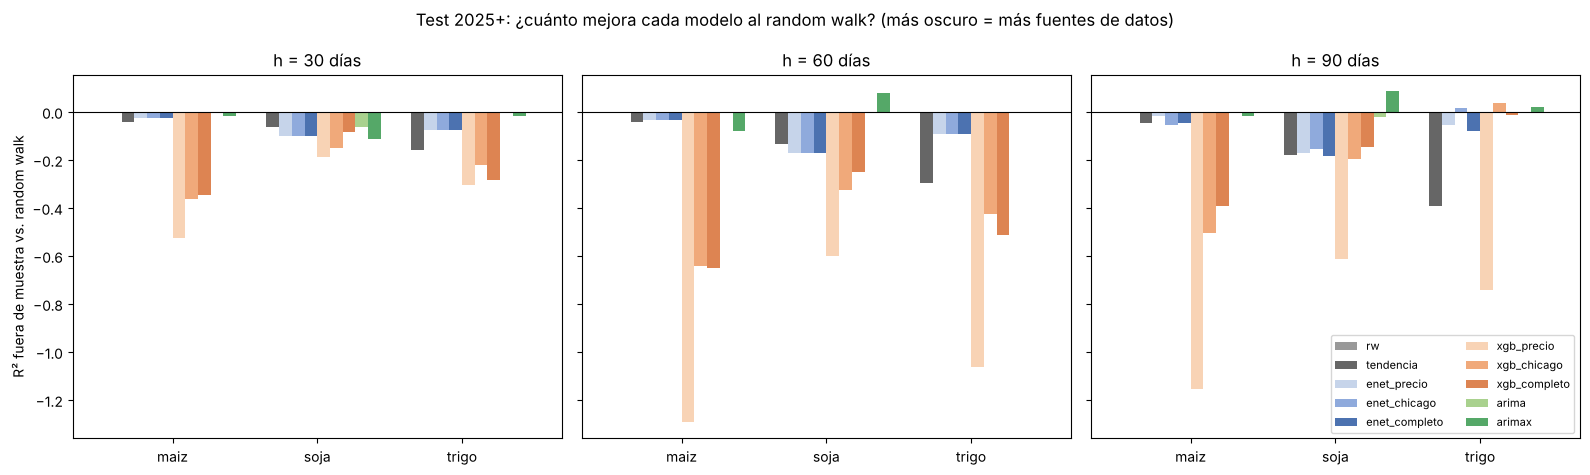

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
colores = {"rw": "#999999", "tendencia": "#666666",
           "enet_precio": "#C6D4EA", "enet_chicago": "#8FAADC", "enet_completo": "#4C72B0",
           "xgb_precio": "#F8D3B5", "xgb_chicago": "#F0A97A", "xgb_completo": "#DD8452",
           "arima": "#A9D18E", "arimax": "#55A868"}
for ax, h in zip(axes, HORIZONTES):
    t = res.xs(h, level="h")["R2_oos_vs_RW"].unstack("modelo")[MODELOS].drop(index="TODAS")
    t.plot.bar(ax=ax, color=[colores[m] for m in MODELOS], width=.88, legend=False)
    ax.axhline(0, color="k", lw=.8)
    ax.set_title(f"h = {h} días"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("R² fuera de muestra vs. random walk")
axes[-1].legend(ncol=2, fontsize=8, loc="lower right")
fig.suptitle("Test 2025+: ¿cuánto mejora cada modelo al random walk? (más oscuro = más fuentes de datos)")
plt.tight_layout(); plt.show()

## 6. ¿Cuánto aporta cada fuente de datos?

Mismo modelo, tres conjuntos de variables que se van sumando: solo precio propio → + Chicago → + clima. Si la línea sube al pasar de un conjunto al siguiente, esa fuente aporta.

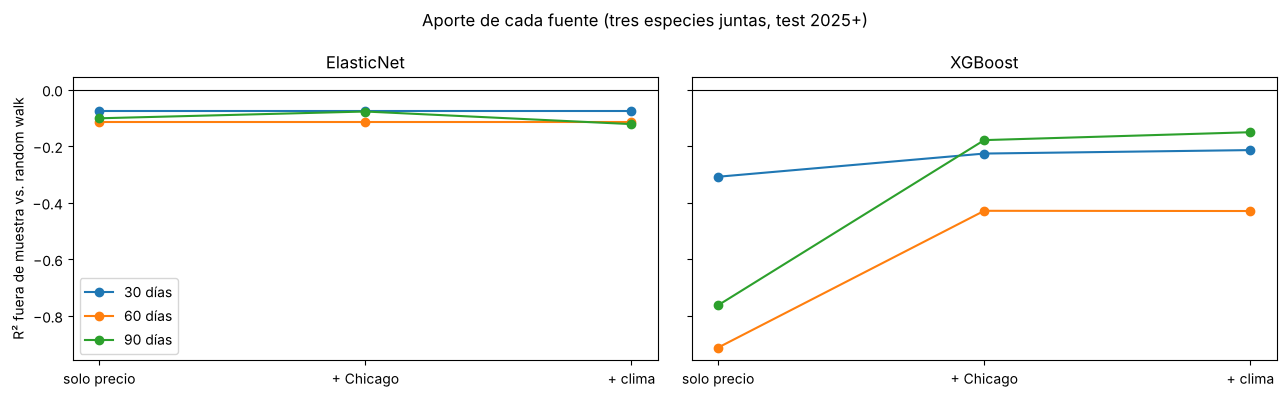

,enet_precio,enet_chicago,enet_completo,xgb_precio,xgb_chicago,xgb_completo
h,,,,,,
30,-0.074,-0.074,-0.074,-0.308,-0.226,-0.214
60,-0.114,-0.114,-0.114,-0.912,-0.429,-0.429
90,-0.102,-0.078,-0.122,-0.762,-0.179,-0.151


In [12]:
aporte = res.xs("TODAS", level="especie")["R2_oos_vs_RW"].unstack("modelo")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, modelo in zip(axes, ["enet", "xgb"]):
    for h in HORIZONTES:
        vals = [aporte.loc[h, f"{modelo}_{cj}"] for cj in CONJUNTOS]
        ax.plot(list(CONJUNTOS), vals, marker="o", label=f"{h} días")
    ax.axhline(0, color="k", lw=.8)
    ax.set_title({"enet": "ElasticNet", "xgb": "XGBoost"}[modelo])
    ax.set_xticks(range(len(CONJUNTOS)), ["solo precio", "+ Chicago", "+ clima"])
axes[0].set_ylabel("R² fuera de muestra vs. random walk"); axes[0].legend()
fig.suptitle("Aporte de cada fuente (tres especies juntas, test 2025+)")
plt.tight_layout(); plt.show()

pd.DataFrame({f"{m}_{cj}": aporte[f"{m}_{cj}"] for m in ["enet", "xgb"] for cj in CONJUNTOS}).round(3)

## 7. Estabilidad por año

Un modelo que gana solo en un año probablemente tuvo suerte con un evento puntual.

In [13]:
filas = []
for (esp, h, anio), g in test.assign(anio=test.fecha.dt.year).groupby(["especie", "h", "anio"]):
    if len(g) < 20:
        continue
    for mo in MODELOS:
        filas.append({"especie": esp, "h": h, "anio": anio, "modelo": mo,
                      "R2_oos_vs_RW": r2_oos(g.y.values, g[f"pred_{mo}"].values)})
pd.DataFrame(filas).pivot_table(index=["especie", "h", "anio"], columns="modelo",
                                values="R2_oos_vs_RW")[MODELOS].round(3)

modelo            rw  tendencia  enet_precio  enet_chicago  enet_completo  xgb_precio  xgb_chicago  xgb_completo  arima  arimax
especie h  anio                                                                                                                
maiz    30 2025  0.0     -0.048       -0.035        -0.035         -0.035      -0.805       -0.587        -0.632  0.000  -0.043
           2026  0.0     -0.027       -0.004        -0.004         -0.004       0.078        0.124         0.269  0.000   0.033
        60 2025  0.0     -0.043       -0.021        -0.021         -0.021      -1.738       -0.890        -0.946  0.000  -0.081
           2026  0.0     -0.038       -0.062        -0.062         -0.062       0.008        0.086         0.208  0.000  -0.076
        90 2025  0.0     -0.032        0.037        -0.011          0.004      -1.277       -0.457        -0.394  0.000  -0.019
           2026  0.0     -0.133       -0.358        -0.339         -0.358      -0.372       -0.795        -0.390  0.000  -0.002
soja    30 2025  0.0     -0.078       -0.113        -0.113         -0.113      -0.269       -0.224        -0.154 -0.080  -0.149
           2026  0.0     -0.006       -0.062        -0.062         -0.062       0.119        0.120         0.172  0.000   0.029
        60 2025  0.0     -0.145       -0.176        -0.176         -0.176      -0.726       -0.392        -0.342 -0.003   0.099
           2026  0.0     -0.059       -0.153        -0.153         -0.153       0.124        0.058         0.274  0.000  -0.030
        90 2025  0.0     -0.196       -0.168        -0.152         -0.186      -0.770       -0.310        -0.269 -0.023   0.097
           2026  0.0     -0.080       -0.178        -0.170         -0.178       0.315        0.471         0.565 -0.001   0.027
trigo   30 2025  0.0     -0.079       -0.030        -0.030         -0.030      -0.616       -0.499        -0.626 -0.003  -0.071
           2026  0.0     -0.255       -0.127        -0.127         -0.127       0.064        0.101         0.115  0.002   0.047
        60 2025  0.0     -0.095        0.021         0.021          0.021      -1.417       -0.882        -1.006 -0.000   0.089
           2026  0.0     -0.531       -0.221        -0.221         -0.221      -0.652        0.101         0.058  0.000  -0.102
        90 2025  0.0      0.012        0.176         0.282          0.137      -0.322        0.166         0.050 -0.002   0.048
           2026  0.0     -0.940       -0.371        -0.340         -0.371      -1.314       -0.135        -0.094 -0.001  -0.013

## 8. Qué aprendieron los modelos (conjunto completo)

- **ElasticNet:** coeficientes estandarizados del modelo entrenado con todos los datos disponibles. Un coeficiente en 0 significa que la regularización descartó la variable. **Si todos dan 0, el modelo no encontró señal estable** y predice solo la tendencia promedio.
- **XGBoost:** importancia por *gain*.

In [14]:
X_COMPLETO = CONJUNTOS["completo"] + VARS_ESP
coefs, imps, MODELOS_FINALES = {}, {}, {}
for h in HORIZONTES:
    d = panel[panel.h == h]
    en = hacer_enet(**MEJORES[("enet", h, "completo")]).fit(d[X_COMPLETO], d.y)
    xg = hacer_xgb(**MEJORES[("xgb", h, "completo")]).fit(d[X_COMPLETO], d.y)
    MODELOS_FINALES[("enet_completo", h)], MODELOS_FINALES[("xgb_completo", h)] = en, xg
    coefs[h] = pd.Series(en[-1].coef_, index=X_COMPLETO)
    imp = xg.get_booster().get_score(importance_type="gain")
    imps[h] = pd.Series(imp).reindex(X_COMPLETO).fillna(0) / max(sum(imp.values()), 1e-12)

coefs = pd.DataFrame(coefs)
print("ElasticNet — coeficientes estandarizados por horizonte (ordenados por |coef| promedio):")
coefs.loc[coefs.abs().mean(axis=1).sort_values(ascending=False).index].round(4)

ElasticNet — coeficientes estandarizados por horizonte (ordenados por |coef| promedio):


,30,60,90
ret_5,0.0,0.0,0.0
ret_21,0.0,0.0,0.0
ret_63,0.0,0.0,0.0
vol_21,0.0,0.0,0.0
dist_ma63,0.0,0.0,0.0
mes_sin,0.0,0.0,0.0
mes_cos,0.0,0.0,0.0
chi_ret_5,0.0,0.0,0.0
chi_ret_21,0.0,0.0,0.0
chi_ret_63,0.0,0.0,0.0


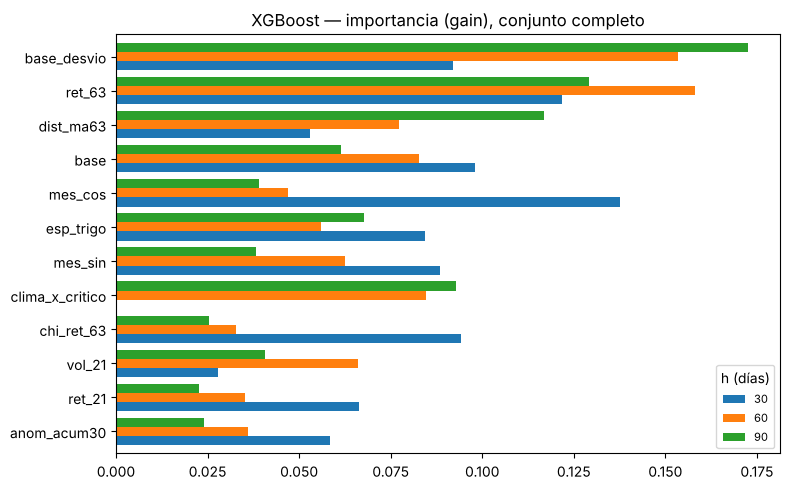

In [15]:
imps = pd.DataFrame(imps)
t = imps.loc[imps.mean(axis=1).sort_values().index].tail(12)
ax = t.plot.barh(figsize=(8, 5), width=.8)
ax.set_title("XGBoost — importancia (gain), conjunto completo"); ax.legend(title="h (días)", fontsize=8)
plt.tight_layout(); plt.show()

### 8.b Sensibilidad a la regularización de ElasticNet

Para distintos α, el R² en **validación** (entrenando con 2023, validando 2024) y en **test** (2025-26).

- Si con α chico la validación da muy negativa, lo que el modelo aprendió de 2023 no se sostuvo en 2024: es el quiebre de régimen (sequía, dólar diferencial).
- **Tabla solo diagnóstica.** Elegir α mirando la columna de test sería usar información del futuro (*data snooping*).

In [16]:
filas = []
for alpha in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]:
    for h in HORIZONTES:
        d = panel[panel.h == h]
        ys, yh = [], []
        for tr, val in folds_tuning(d):
            m = hacer_enet(alpha, 0.5).fit(tr[X_COMPLETO], tr.y)
            ys.append(val.y.values); yh.append(m.predict(val[X_COMPLETO]))
        pred = pd.Series(np.nan, index=d.index)
        for mes, idx_tr, idx_te in folds_walk_forward(d):
            m = hacer_enet(alpha, 0.5).fit(panel.loc[idx_tr, X_COMPLETO], panel.loc[idx_tr, "y"])
            pred.loc[idx_te] = m.predict(panel.loc[idx_te, X_COMPLETO])
        te = d[d.conjunto == "test"]
        filas.append({"alpha": alpha, "h": h,
                      "R2_validacion_2024": r2_oos(np.concatenate(ys), np.concatenate(yh)),
                      "R2_test_2025_26": r2_oos(te.y.values, pred.loc[te.index].values),
                      "variables_activas": int((m[-1].coef_ != 0).sum())})
pd.DataFrame(filas).pivot_table(index="alpha", columns="h",
                                values=["R2_validacion_2024", "R2_test_2025_26", "variables_activas"]).round(2)

R2_test_2025_26             R2_validacion_2024              variables_activas            
h                  30    60    90                 30     60    90                30    60    90
alpha                                                                                          
0.001           -0.64 -0.04 -0.03              -7.30 -15.78 -4.01              17.0  17.0  18.0
0.003           -0.52  0.01  0.00              -4.01  -8.36 -2.29              13.0  16.0  18.0
0.010           -0.31  0.04  0.06              -1.85  -3.13 -1.53               8.0  13.0  13.0
0.030           -0.08 -0.07  0.02              -0.54  -1.30 -1.41               2.0   4.0   5.0
0.100           -0.07 -0.10  0.05              -0.05  -0.07 -0.44               0.0   1.0   3.0
0.300           -0.07 -0.11 -0.12              -0.03  -0.05 -0.01               0.0   0.0   0.0

## 9. Pronóstico desde la última fecha con dato

Precio disponible esperado a 30, 60 y 90 días desde el último día del dataset, con cada modelo entrenado con **todos** los datos.

- **Banda 80%:** se arma con los errores que tuvo ese mismo modelo en el test 2025-26 (percentiles 10 y 90). Es una banda empírica, no un intervalo de confianza formal.
- **ARIMA/ARIMAX** pronostican la cantidad de ruedas que suele haber en h días (≈ 21, 42 y 63).
- **Cuál mirar:** si ningún modelo le ganó al random walk en el test de forma significativa, el pronóstico más honesto es el del random walk (el precio de hoy), con su banda de error. La columna `R2_oos_test` recuerda cómo le fue a cada modelo.

In [17]:
def pronostico_arima(esp, h, nombre):
    # Ajusta ARIMA/ARIMAX con TODA la serie diaria y pronostica S ruedas (las que suele haber en h días)
    cols = EXOG[nombre]
    _, _, pasos, H, _, _ = preparar_serie(esp, h, cols)
    S = int(round(pasos.median()))
    s = diarias[diarias.especie == esp].set_index("fecha")
    lag = s[cols].shift(H) if cols else None
    validas = lag.dropna().index if cols else s.index
    X = lag.loc[validas].values if cols else None
    res = SARIMAX(np.log(s.loc[validas, "P_t"].values), exog=X,
                  order=ORDENES_ELEGIDOS[(nombre, esp, h)], trend="n").fit(disp=False)
    n = len(s)
    X_fut = s[cols].iloc[n - H: n - H + S].values if cols else None   # exógena de hace H ruedas, ya conocida
    return float(res.forecast(steps=S, exog=X_fut)[-1] - np.log(s.P_t.iloc[-1]))

filas = []
for _, u in ultimas.iterrows():
    esp = u.especie
    for h in HORIZONTES:
        g = test[(test.especie == esp) & (test.h == h)]
        X_u = pd.DataFrame([u[X_COMPLETO].astype(float).values], columns=X_COMPLETO)
        preds = {
            "rw": 0.0,
            "tendencia": panel[(panel.h == h) & (panel.especie == esp)].y.mean(),
            "enet_completo": float(MODELOS_FINALES[("enet_completo", h)].predict(X_u)[0]),
            "xgb_completo": float(MODELOS_FINALES[("xgb_completo", h)].predict(X_u)[0]),
            "arima": pronostico_arima(esp, h, "arima"),
            "arimax": pronostico_arima(esp, h, "arimax"),
        }
        for mo, yhat in preds.items():
            resid = g.y - g[f"pred_{mo}"]
            q10, q90 = np.quantile(resid, [0.10, 0.90])
            filas.append({"especie": esp, "h": h, "fecha_objetivo": (u.fecha + pd.Timedelta(days=h)).date(),
                          "modelo": mo, "precio_hoy": u.P_t,
                          "pronostico": u.P_t * np.exp(yhat),
                          "banda_80_baja": u.P_t * np.exp(yhat + q10),
                          "banda_80_alta": u.P_t * np.exp(yhat + q90),
                          "R2_oos_test": r2_oos(g.y.values, g[f"pred_{mo}"].values)})
pronostico = pd.DataFrame(filas)
print(f"Último dato: {ultimas.fecha.max().date()}  (precios en USD/t)")
pronostico.set_index(["especie", "h", "modelo"]).round(1)

Último dato: 2026-09-24  (precios en USD/t)


fecha_objetivo  precio_hoy  pronostico  banda_80_baja  banda_80_alta  R2_oos_test
especie h  modelo                                                                                         
maiz    30 rw                2026-10-24       197.5       197.5          184.3          208.6          0.0
           tendencia         2026-10-24       197.5       196.6          184.7          209.6         -0.0
           enet_completo     2026-10-24       197.5       197.0          185.7          210.0         -0.0
           xgb_completo      2026-10-24       197.5       206.4          193.8          221.7         -0.3
           arima             2026-10-24       197.5       197.5          184.3          208.6          0.0
           arimax            2026-10-24       197.5       197.4          184.8          208.6         -0.0
        60 rw                2026-11-23       197.5       197.5          181.7          210.1          0.0
           tendencia         2026-11-23       197.5       196.1          182.1          211.7         -0.0
           enet_completo     2026-11-23       197.5       196.0          183.6          212.6         -0.0
           xgb_completo      2026-11-23       197.5       207.0          185.7          225.3         -0.7
           arima             2026-11-23       197.5       197.5          181.7          210.1          0.0
           arimax            2026-11-23       197.5       197.7          181.0          212.1         -0.1
        90 rw                2026-12-23       197.5       197.5          177.1          213.3          0.0
           tendencia         2026-12-23       197.5       196.0          178.7          214.6         -0.0
           enet_completo     2026-12-23       197.5       195.2          180.7          216.5         -0.0
           xgb_completo      2026-12-23       197.5       208.0          181.6          228.6         -0.4
           arima             2026-12-23       197.5       197.5          177.1          213.3          0.0
           arimax            2026-12-23       197.5       197.4          177.5          213.1         -0.0
soja    30 rw                2026-10-24       375.0       375.0          355.4          413.1          0.0
           tendencia         2026-10-24       375.0       375.8          357.0          417.3         -0.1
           enet_completo     2026-10-24       375.0       374.0          357.8          416.8         -0.1
           xgb_completo      2026-10-24       375.0       393.4          365.6          432.6         -0.1
           arima             2026-10-24       375.0       375.4          355.7          414.0         -0.1
           arimax            2026-10-24       375.0       376.0          354.9          415.2         -0.1
        60 rw                2026-11-23       375.0       375.0          348.6          428.0          0.0
           tendencia         2026-11-23       375.0       375.3          351.1          435.3         -0.1
           enet_completo     2026-11-23       375.0       372.2          351.7          433.8         -0.2
           xgb_completo      2026-11-23       375.0       393.2          347.1          450.3         -0.3
           arima             2026-11-23       375.0       375.4          348.9          427.3         -0.0
           arimax            2026-11-23       375.0       376.3          348.9          428.9          0.1
        90 rw                2026-12-23       375.0       375.0          338.7          440.5          0.0
           tendencia         2026-12-23       375.0       374.0          344.9          454.2         -0.2
           enet_completo     2026-12-23       375.0       370.6          346.4          450.0         -0.2
           xgb_completo      2026-12-23       375.0       385.0          337.2          466.3         -0.1
           arima             2026-12-23       375.0       375.4          338.0          439.6         -0.0
           arimax            2026-12-23       375.0       369.9   

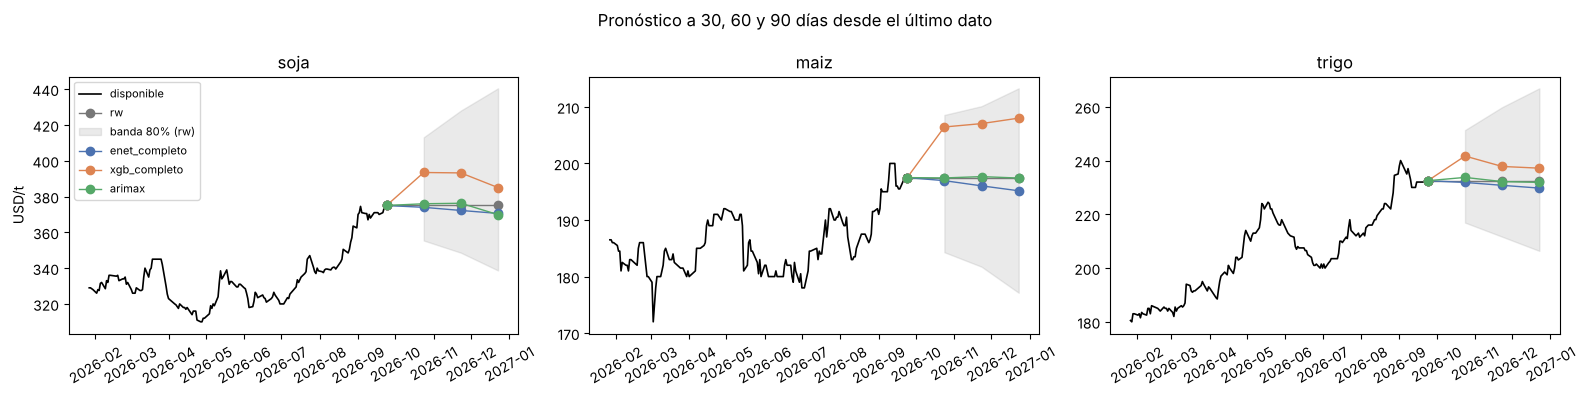

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, esp in zip(axes, ESPECIES):
    hist = diarias[diarias.especie == esp].set_index("fecha").P_t
    hist = hist[hist.index >= ultimas.fecha.max() - pd.Timedelta(days=240)]
    ax.plot(hist.index, hist.values, color="k", lw=1.2, label="disponible")
    u = ultimas[ultimas.especie == esp].iloc[0]
    ax.plot(u.fecha, u.P_t, "ko")
    for mo, c in [("rw", "#777777"), ("enet_completo", "#4C72B0"), ("xgb_completo", "#DD8452"), ("arimax", "#55A868")]:
        p = pronostico[(pronostico.especie == esp) & (pronostico.modelo == mo)]
        fx = [u.fecha] + [u.fecha + pd.Timedelta(days=h) for h in p.h]
        ax.plot(fx, [u.P_t] + list(p.pronostico), marker="o", color=c, lw=1, label=mo)
        if mo == "rw":
            ax.fill_between(fx[1:], p.banda_80_baja, p.banda_80_alta, color=c, alpha=.15, label="banda 80% (rw)")
    ax.set_title(esp); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("USD/t"); axes[0].legend(fontsize=8)
fig.suptitle("Pronóstico a 30, 60 y 90 días desde el último dato")
plt.tight_layout(); plt.show()

## 10. Guardar resultados

In [19]:
cols_pred = [f"pred_{m}" for m in MODELOS]
test[["fecha", "fecha_obj", "especie", "h", "P_t", "P_obj", "y"] + cols_pred].to_csv(os.path.join(RES_DIR, "predicciones_test_sin_futuros.csv"), index=False)
res.to_csv(os.path.join(RES_DIR, "resultados_modelos_sin_futuros.csv"))
pronostico.to_csv(os.path.join(RES_DIR, "pronostico_sin_futuros.csv"), index=False)
pd.Series({str(k): v for k, v in MEJORES.items()}).to_csv(os.path.join(RES_DIR, "hiperparametros_sin_futuros.csv"))
print("Guardado: predicciones_test_sin_futuros.csv, resultados_modelos_sin_futuros.csv, "
      "pronostico_sin_futuros.csv, hiperparametros_sin_futuros.csv")

Guardado: predicciones_test_sin_futuros.csv, resultados_modelos_sin_futuros.csv, pronostico_sin_futuros.csv, hiperparametros_sin_futuros.csv
